# Brain Tumor MRI Classification: Group 4

**TLDR of code production:**
1. Loads in brain MRI pictures (Includes all 4 types: glioma, meningioma, pituitary, and no tumor)
2. Trains one small CNN several times, changing one feature at a time to conduct an ablation study:
   * Augmentation study: randomly tweaks training pictures so the model sees more variety (Models 1 to 4).
   * Normalization study: rescaling pixel values in different ways before the model sees them
3. Repeats each experiment with 3 random seeds (6 total experiments x 3 seeds =  18 runs) and compares the scores

Below is a table outlining the experiements conducted along with the normalization and augmentation techniques implemented:

| Experiment | Normalization | Augmentation |
|---|---|---|
| `baseline_no_normalization` | None | None |
| `model1_baseline` | Dataset | None |
| `baseline_image_normalization` | Image | None |
| `model2_geometric_intensity` | Dataset | Small shifts and rotations, brightness and contrast changes |
| `model3_noise_blur_compression` | Dataset | Gaussian noise, Gaussian blur, JPEG compression |
| `model4_combined` | Dataset | Everything from Models 2 and 3 |

`model1_baseline` is shared by both studies. Normalization is compared on the baseline (no augmentation), and augmentation is compared with dataset normalization.

## Imports & Data Download

In [1]:
import copy, io, json, os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from PIL import Image    # allows us to open and edit pictures
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix

In [2]:
# data download cell, only need to run if you are downloading new data, could also make your own .env file but this is quicker
# just make sure to remove any actual values before saving/sharing.
os.environ['KAGGLE_USERNAME'] = "your_username"
os.environ['KAGGLE_KEY'] = "your_api_key"

data_path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Path to dataset files:", data_path)

Path to dataset files: /home/zev9vw/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2


## Model Basics

In [3]:
seeds = [18, 22, 27]
MAX_EPOCHS = 60 # limit epochs any single run can train, happy to move back down to 30!
PATIENCE = 5 # early stopping: stop a run after this many epochs in a row without validation macro-F1 improvement to speed up the ablation study

# Using the GPU if available, otherwise the CPU will be deployed (much faster w/ GPU!)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

# Keep results consistent across runs
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# The ablation study results dictionary will be saved to this file
experiments = {
    # Normalization study (no augmentation): none vs dataset vs image
    "baseline_no_normalization":    {"normalization": "none",    "augmentation": "none"},
    "model1_baseline":              {"normalization": "dataset", "augmentation": "none"},
    "baseline_image_normalization": {"normalization": "image",   "augmentation": "none"},
    # Augmentation study (dataset normalization)
    "model2_geometric_intensity":    {"normalization": "dataset", "augmentation": "geometric_intensity"},
    "model3_noise_blur_compression": {"normalization": "dataset", "augmentation": "noise_blur_compression"},
    "model4_combined":               {"normalization": "dataset", "augmentation": "combined"},
}

Using device: cuda


## Loading & Splitting the Data; Computing Normalization Values
* **Validation split:** 15% of the Training folder is set aside to check progress during training. The `Testing` folder is only used for the final score
* **Normalization:** pixel values are rescaled using the mean and standard deviation of the training images only

In [4]:
# Loading images without any changes as single grayscale channel and 128 x 128 pixels: baseline transform for all experiments
base_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])
train_dir = os.path.join(data_path, "Training")
test_dir = os.path.join(data_path, "Testing")
full_train = datasets.ImageFolder(root=train_dir, transform=base_transform)

# types of brain tumors (glioma, meningioma, notumor, pituitary)
class_names = full_train.classes

# Stratified Sample of 15%
train_indices, val_indices = train_test_split(
    np.arange(len(full_train)),
    test_size=0.15,
    random_state=22,
    stratify=full_train.targets
)
print("Training images:", len(train_indices), "| Validation images:", len(val_indices))
print("Image classes:", class_names)

Training images: 4760 | Validation images: 840
Image classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [5]:
# Computes the mean and std of the pixel values using the training images
loader = DataLoader(Subset(full_train, train_indices), batch_size=64)

pixel_sum, pixel_squared_sum, total_pixels = 0.0, 0.0, 0
for images, labels in loader:
    pixel_sum += images.sum().item()
    pixel_squared_sum += (images ** 2).sum().item()
    total_pixels += images.numel()

mean = pixel_sum / total_pixels
std = (pixel_squared_sum / total_pixels - mean ** 2) ** 0.5 # variance = mean of squares - square of the mean
training_mean, training_std = [mean], [std]

print("Training Mean:", training_mean)
print("Training Standard Deviation:", training_std)

Training Mean: [0.18348686945538561]
Training Standard Deviation: [0.1934026578437941]


## The Normalization Methods
* **None:** the image stays as is (values between 0 and 1)
* **Dataset:** every image uses the same training-set mean and std
* **Image:** every image is rescaled using its own mean and std

In [6]:
# Methods for normalizing images: none, dataset, or image
class ImageNormalization:
    def __call__(self, image):
        mean = image.mean(dim=(1, 2), keepdim=True)
        std = image.std(dim=(1, 2), keepdim=True, unbiased=False)
        return (image - mean) / (std + 1e-6) # avoid zero division

# Matches the normalization method string to the corresponding transform
def get_normalization(method):
    if method == "none":
        return transforms.Lambda(lambda image: image)
    elif method == "dataset":
        return transforms.Normalize(mean=training_mean, std=training_std)
    elif method == "image":
        return ImageNormalization()
    else:
        raise ValueError("Unknown normalization method") # just in case of method name mistype

## Data Augmentation
* **Model 2:** Deploys shifts, rotations, brightness and contrast
* **Model 3:** Deploys noise, blur and JPEG compression
* **Model 4:** Combined Model 2 and Model 3

In [7]:
# Adds random 'static' to an image tensor, values will be within 0-1
class AddGaussianNoise:
    def __init__(self, std=0.02, p=0.5):
        self.std = std # how strong the noise is
        self.p = p # probability that noise is applied to an image

    def __call__(self, image):
        if random.random() > self.p: # gives a number within 0-1; if it's above p, it will skip the noise this time
            return image
        noisy = image + torch.randn_like(image) * self.std # adds random values from a bell curve
        return noisy.clamp(0.0, 1.0) # keeps pixel values within 0-1

# Adding compression by randomly saving the image as a low-quality JPEG and reloading it
class RandomJPEGCompression:
    def __init__(self, quality_range=(30, 95), p=0.5):
        self.quality_range = quality_range # lower quality = more visible compression damage
        self.p = p

    def __call__(self, image):
        if random.random() > self.p:
            return image
        quality = random.randint(*self.quality_range) # pick a random quality level
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0) # go back to the start so we can read it back
        return Image.open(buffer).convert(image.mode) # reload, keeping the same mode

# Return the two lists of steps for the specific augmentation method
def get_augmentation(method):
    # Model 2: shifts, rotations, brightness and contrast
    geometric_intensity = [
        # degrees=10 -> rotate by a random angle between -10 and +10
        # translate=(0.05, 0.05) -> shift by up to 5% of the width/height
        transforms.RandomAffine(degrees=10, translate=(0.05, 0.05)),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
    ]
    
    # Model 3: blur and JPEG compression on the picture; noise on the tensor
    noise_blur_picture_steps = [
        transforms.RandomApply([transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))], p=0.5),
        RandomJPEGCompression(quality_range=(30, 95), p=0.5),
    ]
    noise_tensor_steps = [AddGaussianNoise(std=0.02, p=0.5)]

    if method == "none":
        return [], []
    elif method == "geometric_intensity":
        return geometric_intensity, []
    elif method == "noise_blur_compression":
        return noise_blur_picture_steps, noise_tensor_steps
    elif method == "combined":
        return geometric_intensity + noise_blur_picture_steps, noise_tensor_steps
    else:
        raise ValueError(f"Unknown augmentation method: {method}")

### Example of Data Augmentation

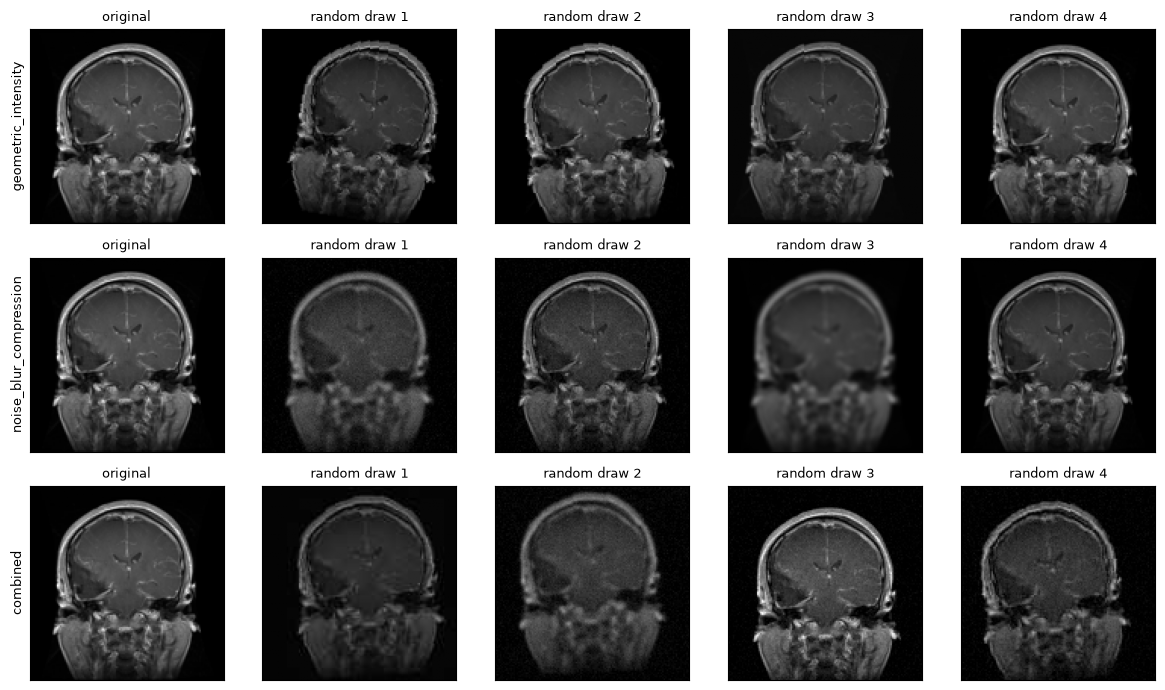

In [8]:
# Example of one training image (left) and 4 random augmented versions of it for each augmentation group
original = Image.open(full_train.samples[0][0]).convert("L").resize((128, 128))

preview_methods = ["geometric_intensity", "noise_blur_compression", "combined"]
fig, axes = plt.subplots(len(preview_methods), 5, figsize=(12, 7))

for row_number, method in enumerate(preview_methods):
    picture_steps, tensor_steps = get_augmentation(method)
    pipeline = transforms.Compose(picture_steps + [transforms.ToTensor()] + tensor_steps)

    axes[row_number][0].imshow(original, cmap="gray")
    axes[row_number][0].set_title("original", fontsize=9)
    axes[row_number][0].set_ylabel(method, fontsize=9)

    for column in range(1, 5):
        augmented = pipeline(original)
        axes[row_number][column].imshow(augmented[0], cmap="gray", vmin=0, vmax=1)
        axes[row_number][column].set_title(f"random draw {column}", fontsize=9)

for axis in axes.flatten():
    axis.set_xticks([])
    axis.set_yticks([])

plt.tight_layout()
plt.show()

## Data loaders
Our DataLoader provides the images to the model in batches of 64
Steps applied to every image:
* Grayscale
* Resize
* Augementation of Picture
* Tensor Conversion
* Augmentation of Tensor 
* Normalization

In [9]:
def make_transform(normalization, augmentation, train):
    picture_steps, tensor_steps = get_augmentation(augmentation) if train else ([], [])
    return transforms.Compose(
        [transforms.Grayscale(num_output_channels=1), transforms.Resize((128, 128))]
        + picture_steps
        + [transforms.ToTensor()]
        + tensor_steps
        + [get_normalization(normalization)]
    )

def make_loaders(normalization, augmentation, seed):
    # Training data is augmented, validation data is not, but both are loaded from the same folder
    train_data = Subset(datasets.ImageFolder(train_dir, make_transform(normalization, augmentation, True)), train_indices)
    val_data = Subset(datasets.ImageFolder(train_dir, make_transform(normalization, "none", False)), val_indices)
    test_data = datasets.ImageFolder(test_dir, make_transform(normalization, "none", False)) # The testing folder is only used for the final evaluation

    generator = torch.Generator()
    generator.manual_seed(seed)

    # shuffle=True so each epoch will see the training image in a new order
    train_loader = DataLoader(train_data, batch_size=64, shuffle=True, generator=generator)
    val_loader = DataLoader(val_data, batch_size=64)
    test_loader = DataLoader(test_data, batch_size=64)
    return train_loader, val_loader, test_loader

## The CNN
We deploy:
* 3x3 convolution (32 channels)
* Three stages of two residual blocks (32, 64, 128 channels)
* Global average pooling
* Linear layer with 4 outputs (about 0.7 million parameters)
* Residual block with a skip connection (this makes our deep networks easier to train)

In [10]:
# Deffining the Residual Block:
class resBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(resBlock, self).__init__()
        # We included a "stride on the first conv of the second/third stages (it halves the image size)
        self.first_conv = nn.Conv2d(in_channels, out_channels, 3, padding=1, stride=stride, bias=False)
        # apply the batchnorm
        self.bn1 = nn.BatchNorm2d(out_channels)
        # apply activation function
        self.relu = nn.ReLU(inplace=True)
        self.second_conv = nn.Conv2d(out_channels, out_channels, 3, padding=1, stride=1, bias=False)
        # apply the second batchnorm
        self.bn2 = nn.BatchNorm2d(out_channels)
        # building the skip connection with a check for any size mismatches
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        # pass x through first conv layer, normalize, apply relu
        holder = self.relu(self.bn1(self.first_conv(x)))
        # apply second conv layer and normalize
        holder = self.bn2(self.second_conv(holder))
        # skip connection, then return the final value after relu
        return self.relu(holder + self.shortcut(x))


class BrainTumorCNN(nn.Module):
    # in_channel = 1 because the images are grayscale
    def __init__(self, num_classes=4, in_channel=1):
        super(BrainTumorCNN, self).__init__()

        # 3x3 convolution with 32 channels
        self.start_block = nn.Sequential(
            nn.Conv2d(in_channel, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        # Three stages, each made of two residual blocks.
        self.stage1 = nn.Sequential(resBlock(32, 32), resBlock(32, 32)) # 32 channels, size unchanged
        self.stage2 = nn.Sequential(resBlock(32, 64, stride=2), resBlock(64, 64)) # 64 channels, size halved
        self.stage3 = nn.Sequential(resBlock(64, 128, stride=2), resBlock(128, 128)) # 128 channels, size halved again

        # Global average pooling; this averages each feature map down to a single number
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        # Final layer: 128 numbers that produce one score per class (the 4 tumor categories)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        holder = self.start_block(x)
        holder = self.stage1(holder)
        holder = self.stage2(holder)
        holder = self.stage3(holder)
        holder = self.avgpool(holder)
        holder = torch.flatten(holder, 1)
        return self.fc(holder)


# Check that the model ran and has ~700K trainable parameters
test_net = BrainTumorCNN()
print("Output shape:", test_net(torch.zeros(2, 1, 128, 128)).shape) # we expect: [2, 4]
print(f"Trainable parameters: {sum(p.numel() for p in test_net.parameters() if p.requires_grad):,}")

Output shape: torch.Size([2, 4])
Trainable parameters: 695,460


## Evaluation:
* **Macro-F1** = the F1 score for each class, averaged (all 4 classes count equally)
* **Early stopping** ends a run once validation macro-F1 stops improving, and keeps the best weights
* **Tumor missed rate** = % of real tumors predicted as no tumor

In [11]:
# Runs the model over a DataLoader and returns the average loss plus every true label and prediction
def evaluate(net, loader, criterion):
    net.eval() # evaluation
    running_loss = 0.0
    all_predictions = [] # keeping all predictions
    all_labels = [] # and every label

    with torch.no_grad(): # decided not to keep gradient tracking
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = net(images)
            running_loss += criterion(outputs, labels).item() * images.size(0)
            all_predictions.extend(outputs.argmax(dim=1).cpu().tolist()) # class with the highest score
            all_labels.extend(labels.cpu().tolist())

    return running_loss / len(all_labels), all_labels, all_predictions


# Turns lists of labels + predictions into the metrics of interest:
def compute_metrics(labels, predictions):
    class_ids = list(range(len(class_names)))

    accuracy = accuracy_score(labels, predictions) * 100.0
    macro_f1 = f1_score(labels, predictions, average="macro", labels=class_ids, zero_division=0) # one precision / recall / F1 value per class
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, labels=class_ids, zero_division=0)
    matrix = confusion_matrix(labels, predictions, labels=class_ids) # rows = true class, columns = predicted class

    # Tumor predicted as no tumor when there was a tumor
    no_tumor_id = class_names.index("notumor")
    tumor_ids = [i for i in class_ids if i != no_tumor_id]
    tumor_missed_rate = 100.0 * matrix[tumor_ids, no_tumor_id].sum() / matrix[tumor_ids, :].sum()

    return {"accuracy": accuracy, "macro_f1": macro_f1, "precision": precision, "recall": recall,
            "f1": f1, "confusion_matrix": matrix, "tumor_missed_rate": tumor_missed_rate}


# Early stopping: Stops training when validation macro-F1 hasn't improved for 5 epochs in a row
class MacroF1EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta # how much the score must rise to count as an improvement
        self.counter = 0 # epochs in a row without improvement
        self.best_f1 = -1.0 # start below any possible score
        self.early_stop = False # becomes True when it's time to stop
        self.best_model_weights = None # copy of the model's weights from the best epoch

    def __call__(self, val_f1, net):
        if val_f1 > self.best_f1 + self.min_delta:
            # Improvement: remembers this score and keeps a copy of the weights
            self.best_f1 = val_f1
            self.counter = 0
            self.best_model_weights = copy.deepcopy(net.state_dict())
        else:
            # No improvement: stops once we run out of 5 epochs in a row without improvement
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

### Training each model:
* Normalization
* Augmentation 
* Seed

### Settings:
* Adam
* Batch size = 64
* Cross-Entropy loss
* Early Stopping

In [12]:
# Trains one model for each normalization x augmentation x seed combo and returns its scores with the settings notesd above
def run_experiment(normalization, augmentation, seed, max_epochs=60, patience=5, learning_rate=1e-3):
    set_seed(seed)

    # Build the data for experiment normalization x augmentation choice
    train_loader, val_loader, test_loader = make_loaders(normalization, augmentation, seed)

    # Identical settings for every model so the comparison is fair
    net = BrainTumorCNN(num_classes=len(class_names), in_channel=1).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate)
    early_stopper = MacroF1EarlyStopping(patience=patience)

    for epoch in range(1, max_epochs + 1):

        # Training
        net.train()
        train_loss, train_total = 0.0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad() # clear old gradients
            outputs = net(images) # make predictions
            loss = criterion(outputs, labels) # measure the error
            loss.backward() # change each weight
            optimizer.step() # update the weights

            train_loss += loss.item() * images.size(0)
            train_total += labels.size(0)

        # Measure progress on validation set
        val_loss, val_labels, val_predictions = evaluate(net, val_loader, criterion)
        val_f1 = compute_metrics(val_labels, val_predictions)["macro_f1"]
        print(f"    epoch {epoch:02d} | train loss {train_loss / train_total:.4f} "
              f"| val loss {val_loss:.4f} | val macro-F1 {val_f1:.4f}")

        early_stopper(val_f1, net)
        if early_stopper.early_stop:
            print(f"    early stopping: no validation macro-F1 improvement for {patience} epochs")
            break

    # Go back to the weights from the best epoch
    net.load_state_dict(early_stopper.best_model_weights)

    # Final scores with the best weights
    _, val_labels, val_predictions = evaluate(net, val_loader, criterion)
    val_metrics = compute_metrics(val_labels, val_predictions)
    _, test_labels, test_predictions = evaluate(net, test_loader, criterion)
    test_metrics = compute_metrics(test_labels, test_predictions)

    # PPlace everything into a dictionary
    outcome = {
        "validation_macro_f1": float(val_metrics["macro_f1"]),
        "test_macro_f1": float(test_metrics["macro_f1"]),
        "accuracy": float(test_metrics["accuracy"]),
        "epochs_trained": epoch,
        "tumor_missed_rate": float(test_metrics["tumor_missed_rate"]),
        # Initially stored as text, will convert to numebrs later
        "confusion_matrix": json.dumps(test_metrics["confusion_matrix"].tolist())
    }
    for i, name in enumerate(class_names):
        outcome[f"precision_{name}"] = float(test_metrics["precision"][i])
        outcome[f"recall_{name}"] = float(test_metrics["recall"][i])
        outcome[f"f1_{name}"] = float(test_metrics["f1"][i])
    return outcome

## Run Experiments
* You can set `QUICK_TEST = True` for a test run to make sure everything works (1 seed x 2 epochs per model)
* Set it back to `False` for the full run (there are 18 training runs, so you must use a GPU!) (WARNING: long compute time ~2-3 hours w/ 1 node, 8 cores, 1 GPU)
* Results are saved to `ablation_results.csv`
* If the cell is stopped and you want to start over from scratch, you have to delete `ablation_results.csv`.

In [13]:
QUICK_TEST = False # Set to true for a test run to check for any errors; False = 18 runs, aka long time

if QUICK_TEST:
    seeds_to_run, epochs_to_run, save_name = seeds[:1], 2, "ablation_results_quicktest.csv"
    results = []
else:
    seeds_to_run, epochs_to_run, save_name = seeds, MAX_EPOCHS, "ablation_results.csv"
    # a saved file exists from an earlier (interrupted) run: continue from it
    results = pd.read_csv(save_name).to_dict("records") if os.path.exists(save_name) else []

finished = {(row["experiment"], row["seed"]) for row in results}

for experiment_name, config in experiments.items():
    for seed in seeds_to_run:

        # Skip it if it already has a result
        if (experiment_name, seed) in finished:
            print(f"Skipping {experiment_name} (seed {seed}) - already done")
            continue

        print(f"\n=== {experiment_name} | seed {seed} ===")
        outcome = run_experiment(config["normalization"], config["augmentation"], seed, max_epochs=epochs_to_run, patience=PATIENCE)
        results.append({"experiment": experiment_name, "seed": seed, **outcome})

        print(f"  --> test macro-F1 {outcome['test_macro_f1']:.4f} | "
              f"test accuracy {outcome['accuracy']:.2f}% | "
              f"tumors missed {outcome['tumor_missed_rate']:.2f}% | epochs {outcome['epochs_trained']}")

        # Save after every run so nothing is lost if the session stops
        pd.DataFrame(results).to_csv(save_name, index=False)

print("\nExperiments finished. Saved to", save_name)


=== baseline_no_normalization | seed 18 ===
    epoch 01 | train loss 0.7228 | val loss 0.7277 | val macro-F1 0.7274
    epoch 02 | train loss 0.5874 | val loss 1.1044 | val macro-F1 0.5034
    epoch 03 | train loss 0.5079 | val loss 2.4274 | val macro-F1 0.2187
    epoch 04 | train loss 0.4485 | val loss 3.6493 | val macro-F1 0.3110
    epoch 05 | train loss 0.4260 | val loss 0.4512 | val macro-F1 0.8161
    epoch 06 | train loss 0.3837 | val loss 2.3067 | val macro-F1 0.3975
    epoch 07 | train loss 0.3695 | val loss 0.9038 | val macro-F1 0.6546
    epoch 08 | train loss 0.3450 | val loss 0.6802 | val macro-F1 0.7299
    epoch 09 | train loss 0.3446 | val loss 0.4255 | val macro-F1 0.8340
    epoch 10 | train loss 0.3078 | val loss 0.6284 | val macro-F1 0.7709
    epoch 11 | train loss 0.2886 | val loss 0.8031 | val macro-F1 0.7163
    epoch 12 | train loss 0.2784 | val loss 1.1689 | val macro-F1 0.6445
    epoch 13 | train loss 0.2618 | val loss 0.4155 | val macro-F1 0.8409
    ep

## Results
Mean +/- SD across seeds, per-class scores, confusion matrices, and the decision rule

In [14]:
# Summary tables (mean ± std across seeds)
done = pd.DataFrame(results)
number_columns = [c for c in done.columns if c not in ("experiment", "seed", "confusion_matrix")]
experiment_order = [name for name in experiments if name in set(done["experiment"])]

# Mean and standard deviation across the seeds for every model.
means = done.groupby("experiment")[number_columns].mean().loc[experiment_order]
stds = done.groupby("experiment")[number_columns].std().loc[experiment_order].fillna(0)

# Table Builder Helper
def mean_std_table(columns, decimals=3):
    text_table = pd.DataFrame(index=experiment_order)
    for column in columns:
        text_table[column] = [f"{means.loc[name, column]:.{decimals}f} ± {stds.loc[name, column]:.{decimals}f}"
                              for name in experiment_order]
    return text_table

print("Main results (test set; mean ± std over seeds)")
display(mean_std_table(["test_macro_f1", "accuracy", "validation_macro_f1", "epochs_trained", "tumor_missed_rate"]))
print("accuracy and tumor_missed_rate are in percent. tumor_missed_rate = % of real tumors predicted as 'notumor'.")

for metric in ["f1", "precision", "recall"]:
    print(f"\nPer-class {metric.upper()} (test set; mean ± std over seeds)")
    class_table = mean_std_table([f"{metric}_{name}" for name in class_names])
    class_table.columns = class_names
    display(class_table)

Main results (test set; mean ± std over seeds)


,test_macro_f1,accuracy,validation_macro_f1,epochs_trained,tumor_missed_rate
baseline_no_normalization,0.765 ± 0.119,77.104 ± 11.401,0.858 ± 0.105,16.333 ± 10.017,9.694 ± 4.439
model1_baseline,0.784 ± 0.097,78.646 ± 10.035,0.863 ± 0.073,16.667 ± 7.572,7.472 ± 2.628
baseline_image_normalization,0.839 ± 0.085,84.125 ± 8.494,0.892 ± 0.073,17.667 ± 11.590,6.306 ± 3.377
model2_geometric_intensity,0.788 ± 0.088,79.208 ± 8.657,0.864 ± 0.065,16.667 ± 8.622,4.472 ± 1.875
model3_noise_blur_compression,0.704 ± 0.139,72.542 ± 11.474,0.811 ± 0.132,12.000 ± 6.557,13.333 ± 6.105
model4_combined,0.763 ± 0.081,77.354 ± 7.785,0.848 ± 0.053,14.333 ± 4.041,10.222 ± 5.800


accuracy and tumor_missed_rate are in percent. tumor_missed_rate = % of real tumors predicted as 'notumor'.

Per-class F1 (test set; mean ± std over seeds)


,glioma,meningioma,notumor,pituitary
baseline_no_normalization,0.715 ± 0.114,0.644 ± 0.190,0.860 ± 0.049,0.844 ± 0.142
model1_baseline,0.699 ± 0.121,0.712 ± 0.119,0.869 ± 0.060,0.856 ± 0.091
baseline_image_normalization,0.789 ± 0.078,0.773 ± 0.144,0.897 ± 0.052,0.898 ± 0.069
model2_geometric_intensity,0.718 ± 0.102,0.712 ± 0.124,0.879 ± 0.052,0.845 ± 0.080
model3_noise_blur_compression,0.596 ± 0.219,0.578 ± 0.163,0.817 ± 0.078,0.825 ± 0.104
model4_combined,0.709 ± 0.078,0.622 ± 0.157,0.839 ± 0.074,0.882 ± 0.035



Per-class PRECISION (test set; mean ± std over seeds)


,glioma,meningioma,notumor,pituitary
baseline_no_normalization,0.773 ± 0.213,0.680 ± 0.172,0.776 ± 0.086,0.889 ± 0.045
model1_baseline,0.957 ± 0.019,0.653 ± 0.175,0.808 ± 0.064,0.885 ± 0.029
baseline_image_normalization,0.903 ± 0.081,0.744 ± 0.137,0.840 ± 0.076,0.905 ± 0.048
model2_geometric_intensity,0.879 ± 0.121,0.679 ± 0.101,0.870 ± 0.049,0.786 ± 0.115
model3_noise_blur_compression,0.875 ± 0.037,0.641 ± 0.089,0.714 ± 0.107,0.759 ± 0.173
model4_combined,0.843 ± 0.062,0.696 ± 0.149,0.763 ± 0.107,0.823 ± 0.023



Per-class RECALL (test set; mean ± std over seeds)


,glioma,meningioma,notumor,pituitary
baseline_no_normalization,0.679 ± 0.041,0.619 ± 0.219,0.970 ± 0.026,0.816 ± 0.212
model1_baseline,0.558 ± 0.138,0.803 ± 0.056,0.939 ± 0.061,0.845 ± 0.181
baseline_image_normalization,0.701 ± 0.076,0.806 ± 0.158,0.965 ± 0.022,0.893 ± 0.098
model2_geometric_intensity,0.608 ± 0.090,0.750 ± 0.157,0.891 ± 0.084,0.920 ± 0.073
model3_noise_blur_compression,0.477 ± 0.234,0.539 ± 0.212,0.959 ± 0.036,0.927 ± 0.040
model4_combined,0.616 ± 0.095,0.588 ± 0.205,0.939 ± 0.077,0.951 ± 0.053


### Confusion Matrix:
For eac model, it adds up the test matrices from all three seeds


baseline_no_normalization (counts summed over 3 seed(s))


,pred glioma,pred meningioma,pred notumor,pred pituitary
true glioma,815,189,144,52
true meningioma,206,743,196,55
true notumor,11,17,1164,8
true pituitary,82,130,9,979



model1_baseline (counts summed over 3 seed(s))


,pred glioma,pred meningioma,pred notumor,pred pituitary
true glioma,670,342,133,55
true meningioma,24,964,131,81
true notumor,0,72,1127,1
true pituitary,4,177,5,1014



baseline_image_normalization (counts summed over 3 seed(s))


,pred glioma,pred meningioma,pred notumor,pred pituitary
true glioma,841,204,113,42
true meningioma,71,967,100,62
true notumor,6,29,1158,7
true pituitary,13,101,14,1072


... (2 outputs left out)


model3_noise_blur_compression (counts summed over 3 seed(s))


,pred glioma,pred meningioma,pred notumor,pred pituitary
true glioma,572,263,189,176
true meningioma,53,647,279,221
true notumor,10,16,1151,23
true pituitary,11,65,12,1112



model4_combined (counts summed over 3 seed(s))


,pred glioma,pred meningioma,pred notumor,pred pituitary
true glioma,739,232,143,86
true meningioma,117,706,222,155
true notumor,12,57,1127,4
true pituitary,9,47,3,1141


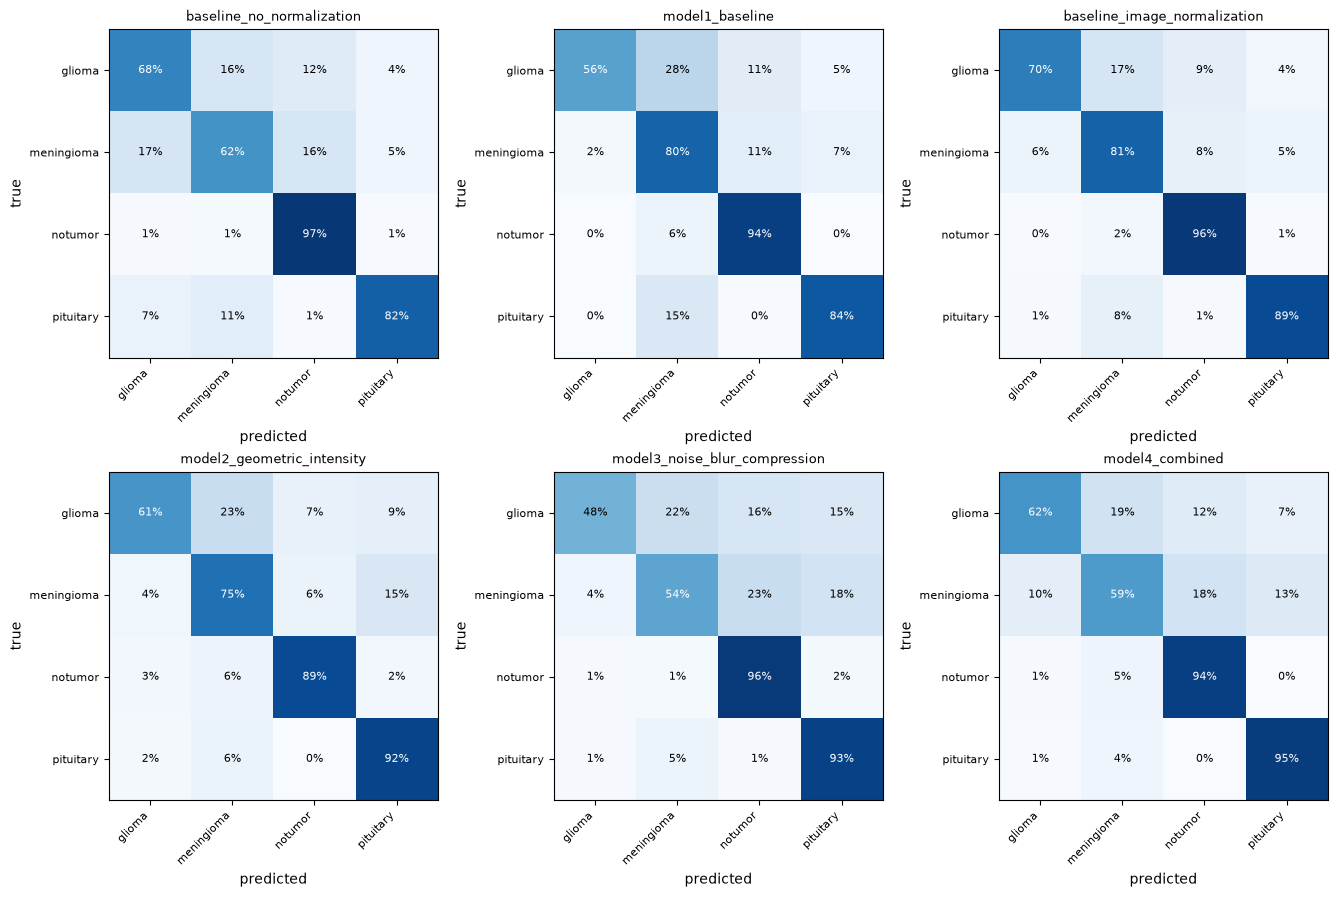

In [15]:
# Confusion matrices: (rows = TRUE class, columns = PREDICTED class; the diagonal = correct predictions)
summed_matrices = {}
for name in experiment_order:
    matrices = [np.array(json.loads(text)) for text in done.loc[done["experiment"] == name, "confusion_matrix"]]
    summed_matrices[name] = sum(matrices)
    print(f"\n{name} (counts summed over {len(matrices)} seed(s))")
    display(pd.DataFrame(summed_matrices[name],
                         index=[f"true {c}" for c in class_names],
                         columns=[f"pred {c}" for c in class_names]))

# Heatmaps: 
columns = 3
rows_needed = -(-len(experiment_order) // columns) # round up
fig, axes = plt.subplots(rows_needed, columns, figsize=(4.5 * columns, 4.5 * rows_needed), squeeze=False)
for axis in axes.flatten()[len(experiment_order):]:
    axis.axis("off") # hide unused squares

for axis, name in zip(axes.flatten(), experiment_order):
    matrix = summed_matrices[name]
    percentages = matrix / matrix.sum(axis=1, keepdims=True) * 100
    axis.imshow(percentages, cmap="Blues", vmin=0, vmax=100)
    axis.set_title(name, fontsize=9)
    axis.set_xticks(range(len(class_names)))
    axis.set_yticks(range(len(class_names)))
    axis.set_xticklabels(class_names, rotation=45, ha="right", fontsize=8)
    axis.set_yticklabels(class_names, fontsize=8)
    axis.set_xlabel("predicted")
    axis.set_ylabel("true")
    # write the percentage inside every square
    for row_index in range(len(class_names)):
        for column_index in range(len(class_names)):
            value = percentages[row_index, column_index]
            axis.text(column_index, row_index, f"{value:.0f}%", ha="center", va="center",
                      color="white" if value > 50 else "black", fontsize=8)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

### The Decision Rule
* An augmented model is better than the baseline if its mean Macro F1 exceeds the baseline's by more than the lager of two SDs across seeds
* If the differences fall within this range, then we claim that the models are performing similarly

In [16]:
def compare_models(name_a, name_b):
    difference = means.loc[name_a, "test_macro_f1"] - means.loc[name_b, "test_macro_f1"]
    margin = max(stds.loc[name_a, "test_macro_f1"], stds.loc[name_b, "test_macro_f1"]) # the larger std

    if difference > margin:
        verdict = f"{name_a} is BETTER"
    elif difference < -margin:
        verdict = f"{name_a} is WORSE"
    else:
        verdict = "EQUIVALENT (within the margin)"
    return difference, margin, verdict

# Augmentation study: each augmented model vs the baseline, and Model 4 vs Models 2 and 3
augmentation_comparisons = [
    ("model2_geometric_intensity",    "model1_baseline"),
    ("model3_noise_blur_compression", "model1_baseline"),
    ("model4_combined",               "model1_baseline"),
    ("model4_combined",               "model2_geometric_intensity"),
    ("model4_combined",               "model3_noise_blur_compression"),
]
# Normalization study: each normalization vs. no normalization
normalization_comparisons = [
    ("model1_baseline",              "baseline_no_normalization"),
    ("baseline_image_normalization", "baseline_no_normalization"),
    ("baseline_image_normalization", "model1_baseline"),
]

def decision_table(comparisons):
    decision_rows = []
    for name_a, name_b in comparisons:
        if name_a in means.index and name_b in means.index: # only compare models that have finished runs (if incomplete)
            difference, margin, verdict = compare_models(name_a, name_b)
            decision_rows.append({"A": name_a, "vs B": name_b,
                                  "mean F1 difference (A - B)": round(difference, 4),
                                  "margin (larger std)": round(margin, 4),
                                  "verdict": verdict})
    return pd.DataFrame(decision_rows)

print("Augmentation study - decision rule on test macro-F1:")
display(decision_table(augmentation_comparisons))
print("Normalization study - decision rule on test macro-F1:")
display(decision_table(normalization_comparisons))

Augmentation study - decision rule on test macro-F1:


,A,vs B,mean F1 difference (A - B),margin (larger std),verdict
0,model2_geometric_intensity,model1_baseline,0.0046,0.0975,EQUIVALENT (within the margin)
1,model3_noise_blur_compression,model1_baseline,-0.0800,0.1386,EQUIVALENT (within the margin)
2,model4_combined,model1_baseline,-0.0208,0.0975,EQUIVALENT (within the margin)
3,model4_combined,model2_geometric_intensity,-0.0254,0.0878,EQUIVALENT (within the margin)
4,model4_combined,model3_noise_blur_compression,0.0592,0.1386,EQUIVALENT (within the margin)


Normalization study - decision rule on test macro-F1:


,A,vs B,mean F1 difference (A - B),margin (larger std),verdict
0,model1_baseline,baseline_no_normalization,0.0183,0.1188,EQUIVALENT (within the margin)
1,baseline_image_normalization,baseline_no_normalization,0.0739,0.1188,EQUIVALENT (within the margin)
2,baseline_image_normalization,model1_baseline,0.0555,0.0975,EQUIVALENT (within the margin)


### Result Plots
* Macro-F1
* per-class F1

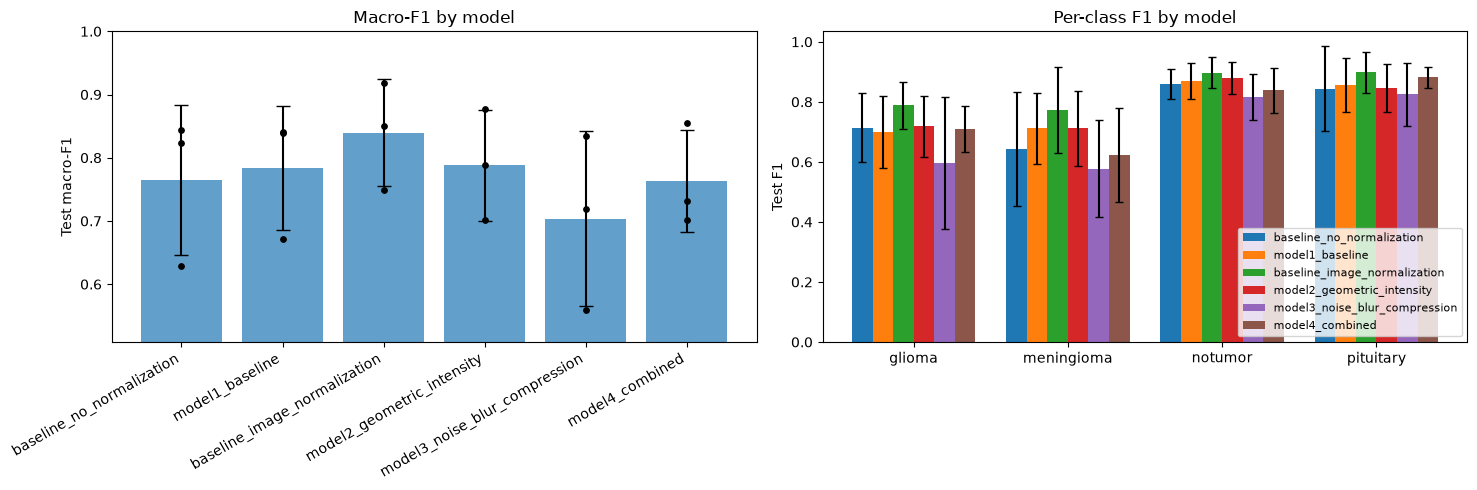

In [17]:
fig, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(15, 5))

# Left: test macro-F1 per model (Bars = mean, black lines = ±1 std, dots = individual seeds)
left_axis.bar(experiment_order, means.loc[experiment_order, "test_macro_f1"],
              yerr=stds.loc[experiment_order, "test_macro_f1"], capsize=5, alpha=0.7)
for position, name in enumerate(experiment_order):
    seed_scores = done.loc[done["experiment"] == name, "test_macro_f1"]
    left_axis.scatter([position] * len(seed_scores), seed_scores, color="black", zorder=3, s=15)
left_axis.set_ylabel("Test macro-F1")
left_axis.set_title("Macro-F1 by model")
plt.setp(left_axis.get_xticklabels(), rotation=30, ha="right")
left_axis.set_ylim(max(0, float(done["test_macro_f1"].min()) - 0.05), 1.0) # zooming the y-axis so small differences are more visible

# Right: per-class F1 (one group of bars per class)
bar_width = 0.8 / len(experiment_order)
for model_number, name in enumerate(experiment_order):
    heights = [means.loc[name, f"f1_{c}"] for c in class_names]
    errors = [stds.loc[name, f"f1_{c}"] for c in class_names]
    positions = [i + model_number * bar_width for i in range(len(class_names))]
    right_axis.bar(positions, heights, width=bar_width, yerr=errors, capsize=3, label=name)
right_axis.set_xticks([i + 0.4 - bar_width / 2 for i in range(len(class_names))])
right_axis.set_xticklabels(class_names)
right_axis.set_ylabel("Test F1")
right_axis.set_title("Per-class F1 by model")
right_axis.legend(fontsize=8)

plt.tight_layout()
plt.savefig("results_plots.png", dpi=150)
plt.show()